In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [50]:
train_df = pd.read_csv("poly_train.csv", header=None, skiprows=1)
test_df  = pd.read_csv("poly_test.csv", header=None, skiprows=1)

train_df = train_df.apply(pd.to_numeric, errors="coerce")
test_df  = test_df.apply(pd.to_numeric, errors="coerce")

X = train_df.iloc[:, :-1].values
y = train_df.iloc[:, -1].values
X_test = test_df.values

print("Train shape:", X.shape)
print("Test shape:", X_test.shape)

Train shape: (1200, 7)
Test shape: (400, 7)


In [51]:
X = np.nan_to_num(X, nan=np.nanmean(X, axis=0))
X_test = np.nan_to_num(X_test, nan=np.nanmean(X, axis=0))
y = np.nan_to_num(y, nan=np.nanmean(y))


In [52]:
X_mean, X_std = X.mean(axis=0), X.std(axis=0)
X = (X - X_mean) / X_std
X_test = (X_test - X_mean) / X_std

y_mean, y_std = y.mean(), y.std()
y = (y - y_mean) / y_std


In [53]:
np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))

X_train, X_val = X[idx[:split]], X[idx[split:]]
y_train, y_val = y[idx[:split]], y[idx[split:]]

In [54]:
def standard_poly(deg, x):

    arr = []

    for i in range(deg + 1):
        for j in range(deg + 1 - i):
            for k in range(deg + 1 - i - j):
                term = (
                    (x[:, 0].reshape(-1, 1) ** i) *
                    (x[:, 1].reshape(-1, 1) ** j) *
                    (x[:, 2].reshape(-1, 1) ** k))
                arr.append(term)

    return np.hstack(arr)

In [55]:
def ridge_regression(X, y, lam):
    I = np.eye(X.shape[1])
    I[0, 0] = 0
    return np.linalg.solve(X.T @ X + lam * I, X.T @ y)

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

Best Degree (based on validation): 7


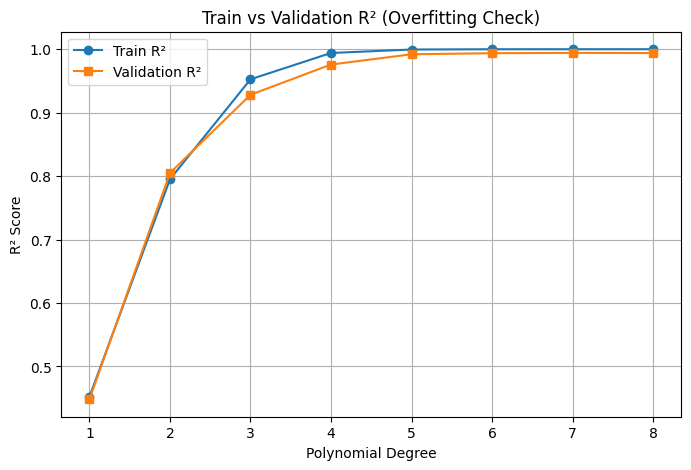

In [56]:
degrees = [1, 2, 3, 4, 5 , 6 , 7,8 ]
train_r2_deg = []
val_r2_deg = []

for d in degrees:
    Xtr = standard_poly(d, X_train)
    Xv  = standard_poly(d, X_val)

    w = ridge_regression(Xtr, y_train, lam=1.0)

    train_r2_deg.append(r2_score(y_train, Xtr @ w))
    val_r2_deg.append(r2_score(y_val, Xv @ w))

best_degree = degrees[np.argmax(val_r2_deg)]
print("Best Degree (based on validation):", best_degree)

# --------- PLOT: TRAIN vs VALIDATION R² ----------
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_r2_deg, marker="o", label="Train R²")
plt.plot(degrees, val_r2_deg, marker="s", label="Validation R²")
plt.xlabel("Polynomial Degree")
plt.ylabel("R² Score")
plt.title("Train vs Validation R² (Overfitting Check)")
plt.legend()
plt.grid(True)
plt.show()


In [57]:
lambdas = [0, 0.01, 0.1, 1, 10, 50]
train_r2, val_r2 = [], []

Xtr = standard_poly(best_degree, X_train)
Xv  = standard_poly(best_degree, X_val)

for lam in lambdas:
    w = ridge_regression(Xtr, y_train, lam)
    train_r2.append(r2_score(y_train, Xtr @ w))
    val_r2.append(r2_score(y_val, Xv @ w))

best_lambda = lambdas[np.argmax(val_r2)]
print("Best Lambda:", best_lambda)




Best Lambda: 0.1


In [58]:
Xtr = standard_poly(best_degree, X_train)
Xv  = standard_poly(best_degree, X_val)
Xt  = standard_poly(best_degree, X_test)

weights = ridge_regression(Xtr, y_train, best_lambda)

print("Final Train R²:", r2_score(y_train, Xtr @ weights))
print("Final Val R²:", r2_score(y_val, Xv @ weights))

Final Train R²: 0.9999767663066734
Final Val R²: 0.9969032196968509


In [59]:
test_pred_scaled = Xt @ weights
test_pred = test_pred_scaled * y_std + y_mean

pd.DataFrame({"prediction": test_pred}).to_csv("my_predictions.csv", index=False)
print("Predictions saved successfully!")

Predictions saved successfully!


Train shape: (1200, 7)
Test shape: (400, 7)


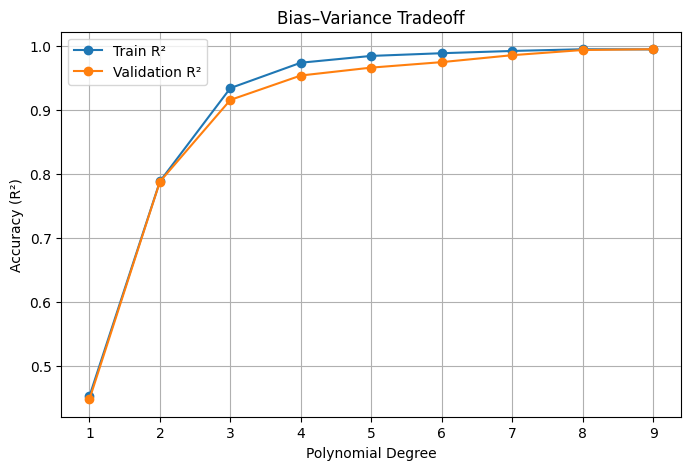


Best Polynomial Degree: 9
Train Accuracy (R²):      0.9965
Validation Accuracy (R²): 0.9963


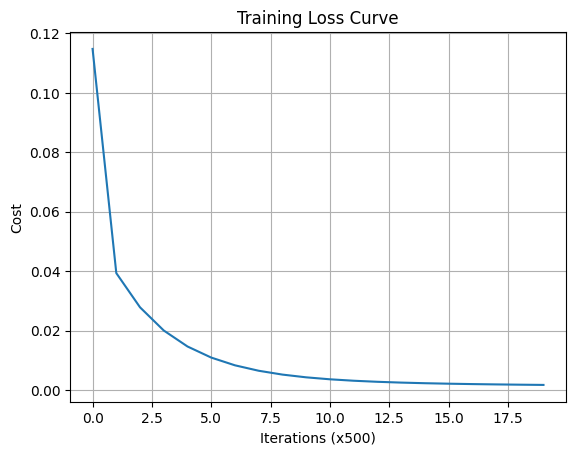


 Predictions saved to final_predictions2.csv


In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


                                         # LOAD DATA

train_df = pd.read_csv("poly_train.csv", header=None, skiprows=1)
test_df  = pd.read_csv("poly_test.csv", header=None, skiprows=1)

train_df = train_df.apply(pd.to_numeric, errors="coerce")
test_df  = test_df.apply(pd.to_numeric, errors="coerce")

X_raw = train_df.iloc[:, :-1].values
y_raw = train_df.iloc[:, -1].values
X_test_raw = test_df.values

print("Train shape:", X_raw.shape)
print("Test shape:", X_test_raw.shape)



X_raw = np.nan_to_num(X_raw, nan=np.nanmean(X_raw, axis=0))
X_test_raw = np.nan_to_num(X_test_raw, nan=np.nanmean(X_test_raw, axis=0))
y_raw = np.nan_to_num(y_raw, nan=np.nanmean(y_raw))


# Z-SCORE NORMALIZATION

def z_score(x):
    mu = np.mean(x, axis=0)
    sigma = np.std(x, axis=0) + 1e-8
    return (x - mu) / sigma, mu, sigma

X, mu, sigma = z_score(X_raw)
X_test = (X_test_raw - mu) / sigma

y_mean, y_std = np.mean(y_raw), np.std(y_raw) + 1e-8
y = (y_raw - y_mean) / y_std


                         # TRAIN–VALIDATION SPLIT

np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))

X_train, X_val = X[idx[:split]], X[idx[split:]]
y_train, y_val = y[idx[:split]], y[idx[split:]]

                            # POLYNOMIAL FEATURES

def standard_poly(deg, x):
    arr = []
    for i in range(deg + 1):
        for j in range(deg + 1 - i):
            for k in range(deg + 1 - i - j):
                term = (
                    (x[:, 0:1] ** i) *
                    (x[:, 1:2] ** j) )
                arr.append(term)
    return np.hstack(arr)


                              #COST & GRADIENT (L2 REGULARIZATION)

def compute_cost(X, y, w, b, lam):
    m = X.shape[0]
    mse = np.sum((X @ w + b - y) ** 2) / (2 * m)
    reg = (lam / (2 * m)) * np.sum(w ** 2)
    return mse + reg

def compute_gradient(X, y, w, b, lam):
    m = X.shape[0]
    error = X @ w + b - y
    dj_dw = (X.T @ error) / m + (lam / m) * w
    dj_db = np.mean(error)
    return dj_dw, dj_db


#                                    GRADIENT DESCENT

def gradient_descent(X, y, alpha, lam, num_iter):
    w = np.zeros(X.shape[1])
    b = 0.0
    cost_hist = []

    for i in range(num_iter):
        dj_dw, dj_db = compute_gradient(X, y, w, b, lam)
        w -= alpha * dj_dw
        b -= alpha * dj_db

        if i % 500 == 0:
            cost_hist.append(compute_cost(X, y, w, b, lam))

    return w, b, cost_hist


#                                    R² SCORE (ACCURACY)

def r2_score(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum(
        (y_true - np.mean(y_true)) ** 2
    )

                                  #BIAS–VARIANCE

degrees = range(1, 10)
train_r2_list, val_r2_list = [], []

for d in degrees:
    Xtr = standard_poly(d, X_train)
    Xv  = standard_poly(d, X_val)

    alpha = 0.005 / (d ** 2)
    lam = 0.05

    w, b, _ = gradient_descent(Xtr, y_train, alpha, lam, num_iter=6000)

    train_r2_list.append(r2_score(y_train, Xtr @ w + b))
    val_r2_list.append(r2_score(y_val, Xv @ w + b))

                                  # TRAIN vs VALIDATION ACCURACY GRAPH

plt.figure(figsize=(8, 5))
plt.plot(degrees, train_r2_list, marker="o", label="Train R²")
plt.plot(degrees, val_r2_list, marker="o", label="Validation R²")
plt.xlabel("Polynomial Degree")
plt.ylabel("Accuracy (R²)")
plt.title("Bias–Variance Tradeoff")
plt.legend()
plt.grid(True)
plt.show()

best_degree = degrees[np.argmax(val_r2_list)]
print("\nBest Polynomial Degree:", best_degree)


                                # FINAL TRAINING (BEST DEGREE)

Xtr_final = standard_poly(best_degree, X_train)
Xv_final  = standard_poly(best_degree, X_val)

alpha = 0.005 / (best_degree ** 2)
lam = 0.05

w_final, b_final, cost_hist = gradient_descent(
    Xtr_final, y_train, alpha, lam, num_iter=10000
)

train_pred = Xtr_final @ w_final + b_final
val_pred   = Xv_final @ w_final + b_final

train_r2 = r2_score(y_train, train_pred)
val_r2   = r2_score(y_val, val_pred)

print(f"Train Accuracy (R²):      {train_r2:.4f}")
print(f"Validation Accuracy (R²): {val_r2:.4f}")


                                         # LOSS vs ITERATIONS

plt.figure()
plt.plot(cost_hist)
plt.xlabel("Iterations (x500)")
plt.ylabel("Cost")
plt.title("Training Loss Curve")
plt.grid(True)
plt.show()


X_full = standard_poly(best_degree, X)

w_full, b_full, _ = gradient_descent(
    X_full, y, alpha, lam, num_iter=12000
)

X_test_poly = standard_poly(best_degree, X_test)
test_pred_scaled = X_test_poly @ w_full + b_full
test_pred = test_pred_scaled * y_std + y_mean

pd.DataFrame({"prediction": test_pred}).to_csv(
    "final_predictions.csv", index=False
)

print("\n Predictions saved to final_predictions2.csv")


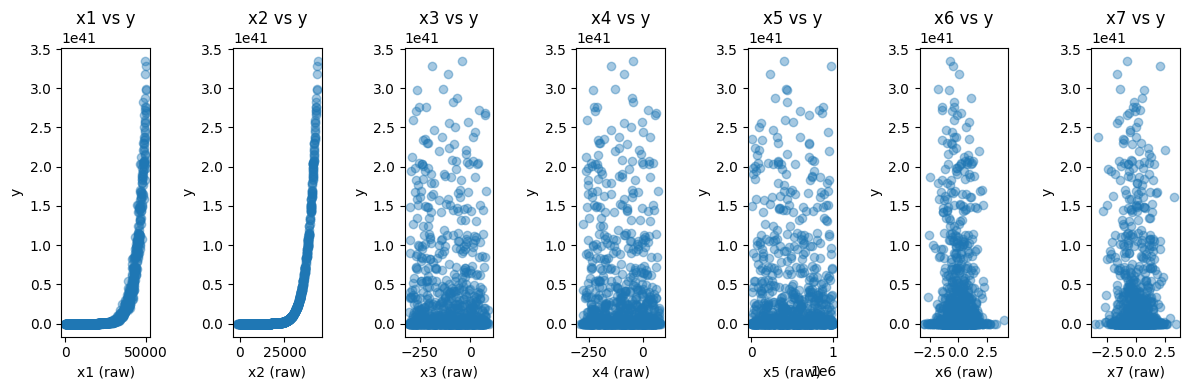

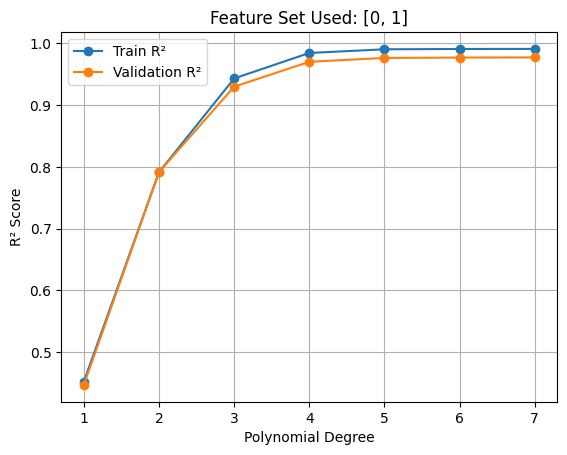


Feature indices used: [0, 1]
Degree 1: Train R² = 0.4523, Val R² = 0.4469
Degree 2: Train R² = 0.7914, Val R² = 0.7916
Degree 3: Train R² = 0.9433, Val R² = 0.9300
Degree 4: Train R² = 0.9846, Val R² = 0.9703
Degree 5: Train R² = 0.9906, Val R² = 0.9766
Degree 6: Train R² = 0.9911, Val R² = 0.9771
Degree 7: Train R² = 0.9912, Val R² = 0.9774

Best Degree based on Validation: 7
Best Validation R²: 0.977423424217421


In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# 1. LOAD DATA
# =====================================================
train_df = pd.read_csv("poly_train.csv", header=None, skiprows=1)
test_df  = pd.read_csv("poly_test.csv", header=None, skiprows=1)

train_df = train_df.apply(pd.to_numeric, errors="coerce")
test_df  = test_df.apply(pd.to_numeric, errors="coerce")

X_raw = train_df.iloc[:, :-1].values
y_raw = train_df.iloc[:, -1].values

# =====================================================
# 2. VISUALIZE RAW FEATURES vs TARGET
# =====================================================
plt.figure(figsize=(12, 4))
for i in range(X_raw.shape[1]):
    plt.subplot(1, X_raw.shape[1], i + 1)
    plt.scatter(X_raw[:, i], y_raw, alpha=0.4)
    plt.xlabel(f"x{i+1} (raw)")
    plt.ylabel("y")
    plt.title(f"x{i+1} vs y")
plt.tight_layout()
plt.show()

# =====================================================
# 3. MANUALLY SELECT FEATURES (ABLATION)
# =====================================================
# Change this to test dropping features
#USE_FEATURES = [0, 1, 2]   # use x1, x2, x3
USE_FEATURES = [0,1]   # uncomment to DROP x3

X = X_raw[:, USE_FEATURES]

# =====================================================
# 4. HANDLE MISSING VALUES
# =====================================================
X = np.nan_to_num(X, nan=np.nanmean(X, axis=0))
y = np.nan_to_num(y_raw, nan=np.nanmean(y_raw))

# =====================================================
# 5. NORMALIZATION
# =====================================================
X_mean, X_std = X.mean(axis=0), X.std(axis=0)
X = (X - X_mean) / X_std

y_mean, y_std = y.mean(), y.std()
y = (y - y_mean) / y_std

# =====================================================
# 6. TRAIN–VALIDATION SPLIT
# =====================================================
np.random.seed(42)
idx = np.random.permutation(len(X))
split = int(0.8 * len(X))

X_train, X_val = X[idx[:split]], X[idx[split:]]
y_train, y_val = y[idx[:split]], y[idx[split:]]

# =====================================================
# 7. POLYNOMIAL FEATURE FUNCTION (GENERAL)
# =====================================================
def polynomial_features(X, degree):
    n_samples, n_features = X.shape
    features = [np.ones((n_samples, 1))]

    for d in range(1, degree + 1):
        for i in range(n_features):
            features.append((X[:, i:i+1]) ** d)

    return np.hstack(features)

# =====================================================
# 8. RIDGE REGRESSION (CLOSED FORM)
# =====================================================
def ridge_regression(X, y, lam):
    I = np.eye(X.shape[1])
    I[0, 0] = 0
    return np.linalg.solve(X.T @ X + lam * I, X.T @ y)

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

# =====================================================
# 9. DEGREE SELECTION (OVERFITTING CHECK)
# =====================================================
degrees = range(1, 8)
train_r2, val_r2 = [], []

for d in degrees:
    Xtr = polynomial_features(X_train, d)
    Xv  = polynomial_features(X_val, d)

    w = ridge_regression(Xtr, y_train, lam=1.0)

    train_r2.append(r2_score(y_train, Xtr @ w))
    val_r2.append(r2_score(y_val, Xv @ w))

# =====================================================
# 10. PLOT TRAIN vs VALIDATION (KEY GRAPH)
# =====================================================
plt.figure()
plt.plot(degrees, train_r2, marker="o", label="Train R²")
plt.plot(degrees, val_r2, marker="o", label="Validation R²")
plt.xlabel("Polynomial Degree")
plt.ylabel("R² Score")
plt.title(f"Feature Set Used: {USE_FEATURES}")
plt.legend()
plt.grid(True)
plt.show()

# =====================================================
# 11. PRINT COMPARISON
# =====================================================
print("\nFeature indices used:", USE_FEATURES)
for d, tr, vr in zip(degrees, train_r2, val_r2):
    print(f"Degree {d}: Train R² = {tr:.4f}, Val R² = {vr:.4f}")

best_d = degrees[np.argmax(val_r2)]
print("\nBest Degree based on Validation:", best_d)
print("Best Validation R²:", max(val_r2))
